# 05. Моделирование

**Цель.** Построить модель, которая по поведению за визит оценивает вероятность покупки. Сравнить бейзлайн, логистическую регрессию и случайный лес, подобрать гиперпараметры, разобраться с дисбалансом классов и порогом. В самом конце один раз проверить выбранную модель на тесте.

**Что уже известно из 04.**
- Основной набор признаков: 9 числовых (страницы, время, показатели отказов и выхода, близость праздника) и 4 категориальных (месяц, тип посетителя, выходной, источник трафика). **Без `PageValues`**, потому что он, скорее всего, содержит выручку самой сессии.
- До подбора гиперпараметров PR-AUC на кросс-валидации: регрессия 0.340, лес 0.388.
- Новые поведенческие признаки прироста не дали.

## Метрики на примере магазина

Представим, что модель будет решать, **кому показать промокод**. Для каждой сессии она выдаёт число от 0 до 1, оценку вероятности покупки. Мы выбираем *порог*: тем, у кого оценка выше порога, показываем промокод.

- **Precision (точность)**: из тех, кому мы показали промокод, какая доля действительно купила. Например, precision 0.5: половина получивших промокод покупатели, половина нет.
- **Recall (полнота)**: из всех, кто купил, какую долю модель отметила. Recall 0.7: модель "поймала" 70% покупателей, 30% пропустила.
- **F1**: компромисс между precision и recall (их среднее гармоническое). F1 высокий, только если обе метрики не слишком низкие.
- **ROC-AUC**: вероятность, что случайный покупатель получит от модели оценку выше, чем случайный не купивший. 0.5 соответствует монетке, 1 идеальной сортировке. От порога не зависит.
- **PR-AUC** (average precision): средний precision по всем возможным порогам, то есть насколько "чистым" получается верх списка, отсортированного по оценке модели. У случайной модели PR-AUC равен доле покупок (0.155), у идеальной он равен 1. При редких покупках эта метрика честнее ROC-AUC, поэтому она у меня главная.

Важная оговорка на будущее. Для промокода высокий precision не всегда хорошо. Если промокод получает тот, кто и так купил бы, магазин просто теряет деньги на скидке. Что выгоднее, решаю в 07 через расчёт прибыли. Здесь задача в том, чтобы научиться хорошо *сортировать* сессии по вероятности покупки.

In [1]:
import json
import sys
import time
import warnings
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore", category=FutureWarning)

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.calibration import calibration_curve
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix, precision_recall_curve, roc_curve
from sklearn.model_selection import GridSearchCV, RandomizedSearchCV

from src.config import (FINAL_MODEL_PATH, MODELS_DIR, OOF_PATH, RANDOM_STATE, TARGET,
                        TEST_PRED_PATH)
from src.data import load_test, load_train, split_xy
from src.evaluation import (cv_permutation_importance, evaluate_oof, get_cv,
                            metrics_at_threshold, threshold_table)
from src.experiments import log_experiment
from src.features import MAIN_CATEGORICAL, MAIN_NUMERIC, make_model_pipeline
from src.plots import AQUA, BLUE, GRAY, INK_2, ORANGE, YELLOW, save_fig, setup_style

setup_style()
pd.set_option("display.precision", 3)

FEATURES = MAIN_NUMERIC + MAIN_CATEGORICAL
X_full, y = split_xy(load_train())
X = X_full[FEATURES]
cv = get_cv()  # 5 фолдов, одинаковых для всех моделей
print(f"train: {X.shape[0]} сессий, {X.shape[1]} признаков; доля покупок {y.mean():.3f}")

summary_rows = []  # сводная таблица моделей
oof = {}           # out-of-fold вероятности каждой модели

def run(name, pipe, data=None):
    row, p = evaluate_oof(name, pipe, X if data is None else data, y, cv)
    summary_rows.append(row)
    oof[name] = p
    return pd.Series(row).drop("модель")

train: 9864 сессий, 13 признаков; доля покупок 0.155


Все оценки в этом ноутбуке, кроме последнего раздела, посчитаны на **кросс-валидации по train** (5 фолдов). Для каждой модели я получаю *out-of-fold* (OOF) предсказания: каждую сессию оценивает модель, которая её не видела при обучении. По ним считаю метрики, порог и все графики. Тест до финального раздела не трогаю.

## 1. Бейзлайн: DummyClassifier

**Идея.** Нужна точка отсчёта: "модель", которая вообще не смотрит на признаки и каждому выдаёт одну и ту же вероятность, равную доле покупок в train. Любая настоящая модель обязана быть заметно лучше.

In [2]:
run("Dummy (доля покупок)", DummyClassifier(strategy="prior"))

ROC-AUC             0.5
ROC-AUC std         0.0
PR-AUC            0.155
PR-AUC std          0.0
порог (max F1)    0.155
precision         0.155
recall              1.0
F1                0.268
dtype: object

**Что увидел.** ROC-AUC 0.500, PR-AUC 0.155 (ровно доля покупок). Максимальный F1 = 0.268 получается, если отметить *всех* как покупателей: precision 0.155, recall 1.

**Что это значит.** Это нижняя граница. Модель с F1 около 0.27 по сути ничего не умеет: такой F1 получается, если просто показать промокод всем.

## 2. Логистическая регрессия

*Логистическая регрессия* это линейная модель: она складывает признаки с весами и превращает сумму в вероятность от 0 до 1. Она простая и хорошо интерпретируется. Внутри Pipeline: логарифм числовых признаков, *стандартизация* (приведение каждого признака к среднему 0 и разбросу 1, чтобы веса были сравнимы) и one-hot для категорий. Всё это обучается только на тренировочной части каждого фолда.

In [3]:
run("ЛР (C=1, по умолчанию)",
    make_model_pipeline(LogisticRegression(max_iter=5000), MAIN_NUMERIC, MAIN_CATEGORICAL))

ROC-AUC           0.759
ROC-AUC std       0.011
PR-AUC            0.339
PR-AUC std        0.009
порог (max F1)    0.185
precision          0.29
recall            0.677
F1                0.406
dtype: object

### Подбор гиперпараметров

*Гиперпараметры* это настройки модели, которые задаю я, а не модель учит сама. У регрессии две важные:
- `C`: сила *регуляризации*, то есть "штрафа" за слишком большие веса. Маленький `C` означает сильный штраф, модель осторожнее и меньше подстраивается под шум;
- `class_weight`: веса классов. `balanced` значит "ошибка на покупателе стоит в 5.5 раза дороже", чтобы модель не игнорировала редкий класс.

Сетка небольшая (10 × 2 = 20 вариантов), поэтому перебираю всё через `GridSearchCV` на тех же 5 фолдах train. Критерий выбора: PR-AUC.

In [4]:
lr_pipe = make_model_pipeline(LogisticRegression(max_iter=5000), MAIN_NUMERIC, MAIN_CATEGORICAL)
lr_grid = {
    "logisticregression__C": [0.001, 0.003, 0.01, 0.03, 0.1, 0.3, 1, 3, 10, 30],
    "logisticregression__class_weight": [None, "balanced"],
}
lr_search = GridSearchCV(lr_pipe, lr_grid, scoring="average_precision", cv=cv, n_jobs=-1)
lr_search.fit(X, y)
print("Лучшие гиперпараметры:", lr_search.best_params_)
print(f"PR-AUC лучшей конфигурации: {lr_search.best_score_:.4f}")

lr_results = pd.DataFrame(lr_search.cv_results_)
# None в параметрах превращаю в строку, иначе pandas считает его пропуском
lr_results["class_weight"] = lr_results["param_logisticregression__class_weight"].astype(object).fillna("None")
(lr_results.pivot_table(index="param_logisticregression__C", columns="class_weight",
                        values="mean_test_score")
 .rename_axis(index="C", columns="class_weight").round(4))

Лучшие гиперпараметры: {'logisticregression__C': 0.03, 'logisticregression__class_weight': None}
PR-AUC лучшей конфигурации: 0.3417


class_weight,None,balanced
C,,
0.001,0.307,0.316
0.003,0.325,0.330
0.010,0.338,0.336
0.030,0.342,0.336
0.100,0.341,0.334
0.300,0.340,0.333
1.000,0.339,0.332
3.000,0.338,0.331
10.000,0.338,0.331


In [5]:
lr_best_params = {k.replace("logisticregression__", ""): v for k, v in lr_search.best_params_.items()}
run("ЛР (подобранная)",
    make_model_pipeline(LogisticRegression(max_iter=5000, **lr_best_params), MAIN_NUMERIC, MAIN_CATEGORICAL))

ROC-AUC           0.757
ROC-AUC std       0.008
PR-AUC            0.342
PR-AUC std        0.012
порог (max F1)    0.198
precision         0.298
recall            0.629
F1                0.404
dtype: object

**Что увидел.** Лучшая конфигурация: `C = 0.03`, `class_weight = None`, PR-AUC 0.342 против 0.339 с настройками по умолчанию. По таблице видно, что без весов классов при `C` от 0.01 до 30 качество почти одинаковое (0.338-0.342). Заметно хуже только при очень сильной регуляризации (`C = 0.001`: 0.307). С `class_weight = balanced` при `C ≥ 0.01` PR-AUC немного ниже (на 0.002-0.007).

**Что это значит.** Подбор гиперпараметров для регрессии почти ничего не дал: модель с 9 + 4 признаками на почти 10 тысячах сессий не переобучается, и штраф ей не особенно нужен.

## 3. Случайный лес

*Случайный лес* состоит из многих деревьев решений. Каждое дерево задаёт набор вопросов вида "товарных страниц больше 20? месяц ноябрь?". Каждое учится на случайной подвыборке сессий и признаков, а ответ леса равен среднему по деревьям. Лес сам находит нелинейности и взаимодействия признаков (например, "новый посетитель в ноябре"), которые регрессия не видит.

Сначала беру лес с настройками sklearn по умолчанию (только 300 деревьев вместо 100 для стабильности).

In [6]:
run("Лес (по умолчанию)",
    make_model_pipeline(RandomForestClassifier(n_estimators=300, n_jobs=1, random_state=RANDOM_STATE),
                        MAIN_NUMERIC, MAIN_CATEGORICAL, log=False, scale=False))

ROC-AUC           0.774
ROC-AUC std       0.006
PR-AUC            0.367
PR-AUC std        0.012
порог (max F1)     0.24
precision         0.337
recall            0.571
F1                0.424
dtype: object

### Подбор гиперпараметров

У леса гиперпараметров больше, и полный перебор занял бы слишком много времени. Поэтому использую `RandomizedSearchCV`: 40 случайных комбинаций из сетки, те же 5 фолдов train, критерий PR-AUC.
- `max_depth`: максимальная глубина дерева (сколько вопросов подряд);
- `min_samples_leaf`: минимум сессий в "листе" дерева. Чем больше, тем грубее и устойчивее правила;
- `max_features`: какую долю признаков дерево рассматривает в каждом разбиении;
- `class_weight`: как у регрессии, плюс `balanced_subsample` (веса считаются для каждого дерева отдельно).

In [7]:
rf_pipe = make_model_pipeline(RandomForestClassifier(n_jobs=1, random_state=RANDOM_STATE),
                              MAIN_NUMERIC, MAIN_CATEGORICAL, log=False, scale=False)
rf_dist = {
    "randomforestclassifier__n_estimators": [300, 500],
    "randomforestclassifier__max_depth": [None, 6, 10, 15, 20],
    "randomforestclassifier__min_samples_leaf": [1, 3, 5, 10, 20, 40],
    "randomforestclassifier__max_features": ["sqrt", 0.3, 0.5, 0.8],
    "randomforestclassifier__class_weight": [None, "balanced", "balanced_subsample"],
}
start = time.time()
rf_search = RandomizedSearchCV(rf_pipe, rf_dist, n_iter=40, scoring="average_precision",
                               cv=cv, n_jobs=-1, random_state=RANDOM_STATE)
rf_search.fit(X, y)
print(f"Время поиска: {time.time() - start:.0f} сек")
print("Лучшие гиперпараметры:", rf_search.best_params_)
print(f"PR-AUC лучшей конфигурации: {rf_search.best_score_:.4f}")

rf_results = pd.DataFrame(rf_search.cv_results_).sort_values("rank_test_score")
param_cols = [c for c in rf_results.columns if c.startswith("param_")]
top = rf_results[param_cols + ["mean_test_score", "std_test_score"]].head(8).copy()
top.columns = [c.replace("param_randomforestclassifier__", "") for c in top.columns]
top[["max_depth", "class_weight"]] = top[["max_depth", "class_weight"]].astype(object).fillna("None")
top

Время поиска: 105 сек
Лучшие гиперпараметры: {'randomforestclassifier__n_estimators': 300, 'randomforestclassifier__min_samples_leaf': 10, 'randomforestclassifier__max_features': 'sqrt', 'randomforestclassifier__max_depth': 20, 'randomforestclassifier__class_weight': None}
PR-AUC лучшей конфигурации: 0.3865


,n_estimators,min_samples_leaf,max_features,max_depth,class_weight,mean_test_score,std_test_score
3,300,10,sqrt,20,None,0.387,0.021
9,300,10,sqrt,15,balanced,0.386,0.022
0,300,5,sqrt,10,balanced,0.385,0.023
4,500,20,0.3,20,balanced,0.384,0.023
18,500,10,0.3,None,balanced,0.384,0.021
27,300,10,0.3,20,None,0.384,0.024
13,500,5,sqrt,10,None,0.383,0.023
11,300,5,0.3,20,balanced,0.383,0.016


In [8]:
# Как PR-AUC зависит от min_samples_leaf: среднее по всем попробованным комбинациям
leaf_effect = (rf_results.groupby("param_randomforestclassifier__min_samples_leaf")["mean_test_score"]
               .agg(["mean", "max", "size"]).rename_axis("min_samples_leaf"))
leaf_effect.round(4)

,mean,max,size
min_samples_leaf,,,
1,0.371,0.381,6
3,0.373,0.381,10
5,0.376,0.385,7
10,0.380,0.387,8
20,0.379,0.384,5
40,0.370,0.376,4


In [9]:
rf_best_params = {k.replace("randomforestclassifier__", ""): v for k, v in rf_search.best_params_.items()}
rf_tuned_pipe = make_model_pipeline(
    RandomForestClassifier(n_jobs=1, random_state=RANDOM_STATE, **rf_best_params),
    MAIN_NUMERIC, MAIN_CATEGORICAL, log=False, scale=False)
run("Лес (подобранный)", rf_tuned_pipe)

ROC-AUC           0.786
ROC-AUC std       0.008
PR-AUC            0.387
PR-AUC std        0.021
порог (max F1)    0.224
precision         0.345
recall            0.587
F1                0.435
dtype: object

**Что увидел.** Лучшая конфигурация: 300 деревьев, `max_depth = 20`, `min_samples_leaf = 10`, `max_features = 'sqrt'`, без весов классов. PR-AUC 0.387 против 0.367 у леса по умолчанию. Главное, что делает подбор: запрещает слишком мелкие листья. При `min_samples_leaf = 1` лучший результат 0.381, при 10 он равен 0.387. Лес по умолчанию дорастает до листьев из одной сессии и запоминает шум train.

**Что это значит.** Подбор дал лесу +0.020 PR-AUC, заметно больше, чем регрессии. Лес лучше регрессии на 0.045 (0.387 против 0.342) PR-AUC. Гипотеза "лес лучше линейной модели" подтвердилась, хотя и без огромного отрыва.

Оговорка: PR-AUC 0.387 это лучший результат из 40 попыток на одних и тех же фолдах, поэтому он немного оптимистичен. Ещё одна причина держать тест отдельно.

## 4. Контроль: градиентный бустинг

**Идея.** Вдруг лес не предел и другая сильная модель на этих признаках даст больше? Проверяю `HistGradientBoostingClassifier` из sklearn (бустинг строит деревья последовательно, каждое исправляет ошибки предыдущих) с небольшим случайным поиском (25 комбинаций). Это не основная часть плана, а проверка "потолка".

In [10]:
hgb_pipe = make_model_pipeline(HistGradientBoostingClassifier(random_state=RANDOM_STATE),
                               MAIN_NUMERIC, MAIN_CATEGORICAL, log=False, scale=False)
hgb_dist = {
    "histgradientboostingclassifier__learning_rate": [0.02, 0.05, 0.1],
    "histgradientboostingclassifier__max_leaf_nodes": [7, 15, 31],
    "histgradientboostingclassifier__min_samples_leaf": [20, 50, 100],
    "histgradientboostingclassifier__l2_regularization": [0, 1, 10],
    "histgradientboostingclassifier__max_iter": [100, 300],
}
hgb_search = RandomizedSearchCV(hgb_pipe, hgb_dist, n_iter=25, scoring="average_precision",
                                cv=cv, n_jobs=-1, random_state=RANDOM_STATE)
hgb_search.fit(X, y)
print("Лучшие гиперпараметры:", hgb_search.best_params_)
hgb_best_params = {k.replace("histgradientboostingclassifier__", ""): v
                   for k, v in hgb_search.best_params_.items()}
run("Бустинг (подобранный)", make_model_pipeline(
    HistGradientBoostingClassifier(random_state=RANDOM_STATE, **hgb_best_params),
    MAIN_NUMERIC, MAIN_CATEGORICAL, log=False, scale=False))

Лучшие гиперпараметры: {'histgradientboostingclassifier__min_samples_leaf': 100, 'histgradientboostingclassifier__max_leaf_nodes': 7, 'histgradientboostingclassifier__max_iter': 300, 'histgradientboostingclassifier__learning_rate': 0.1, 'histgradientboostingclassifier__l2_regularization': 1}


ROC-AUC           0.788
ROC-AUC std        0.01
PR-AUC            0.377
PR-AUC std        0.016
порог (max F1)    0.204
precision         0.334
recall            0.632
F1                0.437
dtype: object

**Что увидел.** У бустинга PR-AUC 0.377, на 0.010 ниже, чем у леса (0.387). По ROC-AUC (0.788 против 0.786) и максимальному F1 (0.437 против 0.435) бустинг, наоборот, чуть выше леса.

**Что это значит.** Разница в обе стороны меньше разброса между фолдами (std PR-AUC 0.016-0.021). Бустинг на этих признаках не лучше и не хуже леса: похоже, потолок задают признаки, а не модель. Оставляю лес, потому что он лучше по главной метрике, выбранной заранее (PR-AUC).

## 5. Дисбаланс: веса классов или порог?

**Идея.** Дисбаланс можно учитывать двумя способами:
1. **веса классов** (`class_weight="balanced"`): при обучении ошибка на покупателе "стоит" в 5.5 раз дороже;
2. **порог**: модель учится как обычно, а потом я сдвигаю порог "купит / не купит" ниже 0.5.

Сравниваю оба способа на подобранном лесе: всё одинаково, кроме `class_weight`.

In [11]:
rf_balanced_params = {**rf_best_params, "class_weight": "balanced"}
rf_balanced_pipe = make_model_pipeline(
    RandomForestClassifier(n_jobs=1, random_state=RANDOM_STATE, **rf_balanced_params),
    MAIN_NUMERIC, MAIN_CATEGORICAL, log=False, scale=False)
run("Лес (подобранный) + balanced", rf_balanced_pipe)

compare_cw = pd.DataFrame(summary_rows).set_index("модель").loc[
    ["Лес (подобранный)", "Лес (подобранный) + balanced"],
    ["ROC-AUC", "PR-AUC", "порог (max F1)", "precision", "recall", "F1"]]
compare_cw["средняя оценка модели"] = [oof["Лес (подобранный)"].mean(),
                                       oof["Лес (подобранный) + balanced"].mean()]
compare_cw["доля покупок на самом деле"] = y.mean()
compare_cw

,ROC-AUC,PR-AUC,порог (max F1),precision,recall,F1,средняя оценка модели,доля покупок на самом деле
модель,,,,,,,,
Лес (подобранный),0.786,0.387,0.224,0.345,0.587,0.435,0.155,0.155
Лес (подобранный) + balanced,0.786,0.385,0.532,0.333,0.640,0.438,0.385,0.155


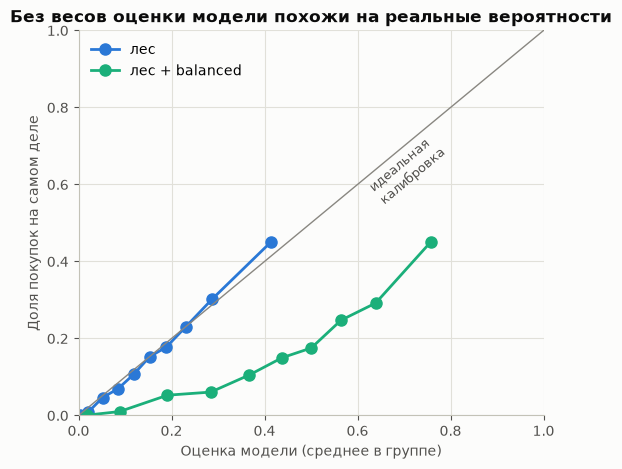

In [12]:
fig, ax = plt.subplots(figsize=(6, 5))
for name, color in [("Лес (подобранный)", BLUE), ("Лес (подобранный) + balanced", AQUA)]:
    frac_pos, mean_pred = calibration_curve(y, oof[name], n_bins=10, strategy="quantile")
    ax.plot(mean_pred, frac_pos, marker="o", markersize=8, color=color,
            label=name.replace("Лес (подобранный)", "лес"))
ax.plot([0, 1], [0, 1], color=GRAY, linewidth=1)
ax.text(0.62, 0.55, "идеальная\nкалибровка", color=INK_2, fontsize=9, rotation=40)
ax.set_xlim(0, 1)
ax.set_ylim(0, 1)
ax.set_xlabel("Оценка модели (среднее в группе)")
ax.set_ylabel("Доля покупок на самом деле")
ax.set_title("Без весов оценки модели похожи на реальные вероятности")
ax.legend(loc="upper left")
save_fig(fig, "05_calibration")
plt.show()

*Калибровка* показывает, можно ли верить оценке модели как вероятности. Сессии делятся на 10 групп по оценке модели, и для каждой группы сравнивается средняя оценка с реальной долей покупок. Если модель говорит "30%" и среди таких сессий действительно покупают около 30%, точки лежат на диагонали.

**Что увидел.** С весами PR-AUC 0.385 против 0.387 без них, а максимальный F1 практически одинаковый (0.438 против 0.435). Отличаются пороги (0.532 против 0.224) и сами оценки: без весов средняя оценка 0.155 (реальная доля покупок 0.155), с весами 0.385. На графике калибровки лес без весов идёт почти по диагонали, а с весами систематически завышает вероятности.

**Что это значит.** Веса классов не делают модель лучше в сортировке. Они просто "сдвигают" все оценки вверх, и тот же результат даёт более низкий порог. Я выбираю **модель без весов + подбор порога**. Её оценки можно читать как вероятности, а это понадобится в 07 при расчёте прибыли ("у этой сессии вероятность покупки 30%").

## 6. Сводная таблица моделей (кросс-валидация на train)

Для справки добавляю **лес с `PageValues`** с теми же гиперпараметрами, это "оптимистичная верхняя граница" из 04. В выборе модели он не участвует.

In [13]:
FEATURES_PV = MAIN_NUMERIC + ["PageValues"] + MAIN_CATEGORICAL
rf_pv_pipe = make_model_pipeline(
    RandomForestClassifier(n_jobs=1, random_state=RANDOM_STATE, **rf_best_params),
    MAIN_NUMERIC + ["PageValues"], MAIN_CATEGORICAL, log=False, scale=False)
run("Справка: лес + PageValues (утечка)", rf_pv_pipe, data=X_full[FEATURES_PV])

summary = pd.DataFrame(summary_rows).set_index("модель")
summary

,ROC-AUC,ROC-AUC std,PR-AUC,PR-AUC std,порог (max F1),precision,recall,F1
модель,,,,,,,,
Dummy (доля покупок),0.500,0.000,0.155,1.972e-04,0.155,0.155,1.000,0.268
"ЛР (C=1, по умолчанию)",0.759,0.011,0.339,9.357e-03,0.185,0.290,0.677,0.406
ЛР (подобранная),0.757,0.008,0.342,1.155e-02,0.198,0.298,0.629,0.404
Лес (по умолчанию),0.774,0.006,0.367,1.162e-02,0.240,0.337,0.571,0.424
Лес (подобранный),0.786,0.008,0.387,2.112e-02,0.224,0.345,0.587,0.435
Бустинг (подобранный),0.788,0.010,0.377,1.621e-02,0.204,0.334,0.632,0.437
Лес (подобранный) + balanced,0.786,0.009,0.385,2.235e-02,0.532,0.333,0.640,0.438
Справка: лес + PageValues (утечка),0.932,0.004,0.751,1.783e-02,0.319,0.641,0.751,0.691


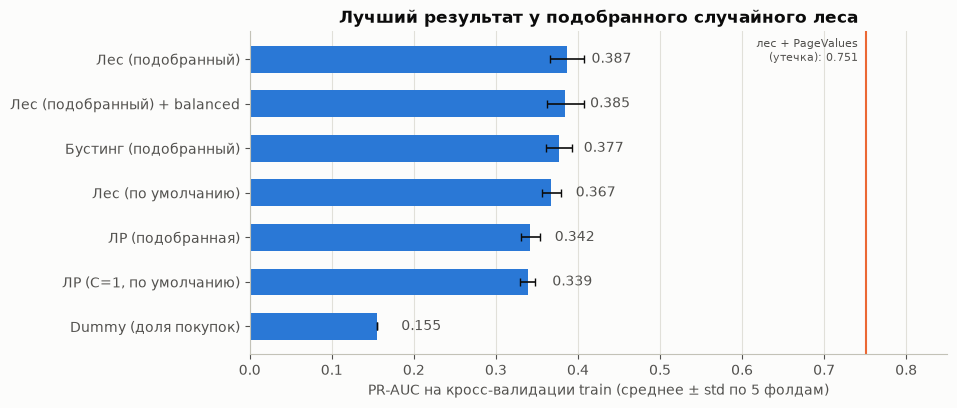

In [14]:
plot_df = summary.drop(index="Справка: лес + PageValues (утечка)").sort_values("PR-AUC")
fig, ax = plt.subplots(figsize=(9, 4.2))
y_pos = np.arange(len(plot_df))
ax.barh(y_pos, plot_df["PR-AUC"], xerr=plot_df["PR-AUC std"], color=BLUE, height=0.6,
        error_kw={"ecolor": "#0b0b0b", "elinewidth": 1.2, "capsize": 3})
for yp, v in zip(y_pos, plot_df["PR-AUC"]):
    ax.text(v + 0.03, yp, f"{v:.3f}", va="center", color=INK_2)
pv_value = summary.loc["Справка: лес + PageValues (утечка)", "PR-AUC"]
ax.axvline(pv_value, color=ORANGE, linewidth=1.5)
ax.text(pv_value - 0.01, len(plot_df) - 0.5, f"лес + PageValues\n(утечка): {pv_value:.3f}",
        ha="right", va="top", color=INK_2, fontsize=8)
ax.set_yticks(y_pos)
ax.set_yticklabels(plot_df.index)
ax.set_xlim(0, 0.85)
ax.set_xlabel("PR-AUC на кросс-валидации train (среднее ± std по 5 фолдам)")
ax.set_title("Лучший результат у подобранного случайного леса")
ax.grid(axis="y", visible=False)
save_fig(fig, "05_model_comparison")
plt.show()

In [15]:
changes = {
    "Dummy (доля покупок)": "всем одна и та же вероятность, равная доле покупок",
    "ЛР (C=1, по умолчанию)": "log + стандартизация + one-hot, C=1",
    "ЛР (подобранная)": f"GridSearchCV по C и class_weight → {lr_best_params}",
    "Лес (по умолчанию)": "300 деревьев, остальное по умолчанию (листья до 1 сессии)",
    "Лес (подобранный)": f"RandomizedSearchCV, 40 комбинаций → {rf_best_params}",
    "Бустинг (подобранный)": "HistGradientBoosting, RandomizedSearchCV, 25 комбинаций",
    "Лес (подобранный) + balanced": "тот же лес, class_weight='balanced'",
    "Справка: лес + PageValues (утечка)": "тот же лес + PageValues",
}
for i, (name, row) in enumerate(summary.iterrows(), start=8):
    log_experiment(
        str(i), "05", f"Модель: {name}",
        changes[name],
        f"PR-AUC {row['PR-AUC']:.3f} ± {row['PR-AUC std']:.3f}, ROC-AUC {row['ROC-AUC']:.3f}, "
        f"max F1 {row['F1']:.3f}",
        {
            "Dummy (доля покупок)": "точка отсчёта",
            "ЛР (C=1, по умолчанию)": "основа для подбора",
            "ЛР (подобранная)": "отказываюсь: хуже леса, оставляю как интерпретируемую альтернативу",
            "Лес (по умолчанию)": "основа для подбора: листья из одной сессии, переобучается",
            "Лес (подобранный)": "оставляю: лучшая модель, финальная",
            "Бустинг (подобранный)": "отказываюсь: не лучше леса",
            "Лес (подобранный) + balanced": "отказываюсь: качество то же, вероятности завышены; порог даёт тот же эффект",
            "Справка: лес + PageValues (утечка)": "не используется: верхняя граница с утечкой",
        }[name],
    )

**Что увидел.** Все модели заметно лучше бейзлайна (PR-AUC 0.155). Регрессия 0.342, лес по умолчанию 0.367, подобранный лес 0.387, бустинг 0.377. По ROC-AUC: регрессия 0.757, лес 0.786, бустинг 0.788. Разница между лесом и регрессией (0.045) больше разброса между фолдами, а между лесом и бустингом нет. Модель с утечкой (`PageValues`) даёт 0.751, почти вдвое больше любой честной модели.

**Итог выбора: подобранный случайный лес без весов классов.** Он лучше остальных по PR-AUC и ROC-AUC, а его вероятности хорошо откалиброваны.

## 7. Выбор порога

**Идея.** Модель выдаёт вероятность, а для решения "показывать промокод или нет" нужен порог. Чем ниже порог, тем больше покупателей мы "ловим" (recall растёт), но тем больше среди отмеченных случайных людей (precision падает). Выбираю порог по OOF-предсказаниям на train, чтобы потом проверить его на тесте без подгонки.

Как техническое значение по умолчанию беру порог, при котором F1 максимальна. Порог для промокода по прибыли подберу в 07: там важны деньги, а не F1.

Порог с максимальным F1 по OOF: 0.224


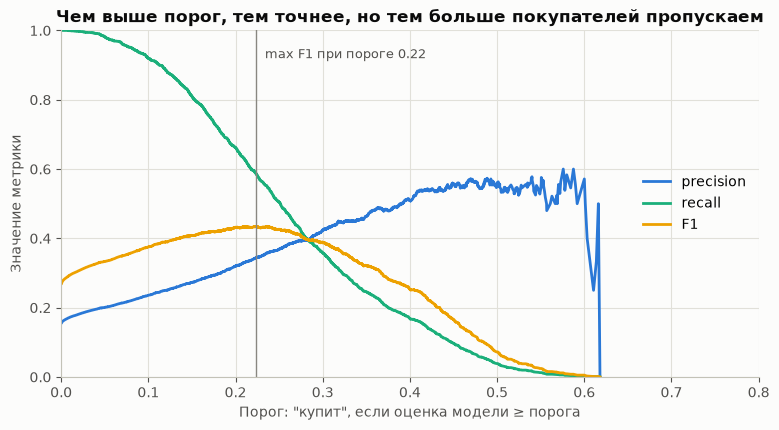

,precision,recall,F1,доля отмеченных
порог,,,,
0.100,0.236,0.919,0.375,0.604
0.200,0.320,0.663,0.432,0.320
0.224,0.345,0.587,0.435,0.263
0.400,0.509,0.168,0.253,0.051
0.500,0.551,0.039,0.072,0.011
0.600,0.571,0.003,0.005,0.001


In [16]:
final_name = "Лес (подобранный)"
p_oof = oof[final_name]
threshold = summary.loc[final_name, "порог (max F1)"]
print(f"Порог с максимальным F1 по OOF: {threshold:.3f}")

prec, rec, thr = precision_recall_curve(y, p_oof)
f1 = 2 * prec * rec / np.clip(prec + rec, 1e-12, None)
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(thr, prec[:-1], color=BLUE, label="precision")
ax.plot(thr, rec[:-1], color=AQUA, label="recall")
ax.plot(thr, f1[:-1], color=YELLOW, label="F1")
ax.axvline(threshold, color=GRAY, linewidth=1)
ax.text(threshold + 0.01, 0.92, f"max F1 при пороге {threshold:.2f}", color=INK_2, fontsize=9)
ax.set_xlim(0, 0.8)
ax.set_ylim(0, 1)
ax.set_xlabel('Порог: "купит", если оценка модели ≥ порога')
ax.set_ylabel("Значение метрики")
ax.set_title("Чем выше порог, тем точнее, но тем больше покупателей пропускаем")
ax.legend(loc="center right")
save_fig(fig, "05_threshold_tradeoff")
plt.show()

threshold_table(y, p_oof, [0.1, 0.2, threshold, 0.4, 0.5, 0.6]).round(3)

**Что увидел.** Максимальный F1 = 0.435 при пороге 0.224: precision 0.345, recall 0.587, отмечено 26.3% сессий. При пороге 0.5 precision выше (0.551), но recall падает до 3.9%. При пороге 0.1 модель ловит 91.9% покупателей, но отмечает 60.4% всех сессий.

**Что это значит.** Модель не умеет надёжно отделять покупателей: даже при лучшем компромиссе примерно две трети (65.5%) отмеченных оказываются не покупателями. Для промокода это не обязательно плохо: именно среди них могут быть "почти-покупатели", которых стоит дожать. Этим сегментом займусь в 06.

## 8. Какие признаки важны: permutation importance

**Идея.** *Permutation importance* показывает, на что опирается модель. Берём признак и случайно перемешиваем его значения между сессиями, ломая его связь с покупкой. Если качество модели сильно падает, признак важен. Считаю на отложенных фолдах train: модель учится на 4/5, важность меряется на оставшейся 1/5. Метрика: падение PR-AUC.

In [17]:
importance = cv_permutation_importance(rf_tuned_pipe, X, y, cv, scoring="average_precision", n_repeats=5)
importance.round(4)

,важность,std по фолдам
Month,7.140e-02,1.980e-02
ExitRates,5.390e-02,1.820e-02
ProductRelated_Duration,5.210e-02,1.050e-02
VisitorType,2.500e-02,1.320e-02
BounceRates,1.690e-02,1.010e-02
Administrative,1.370e-02,8.100e-03
ProductRelated,1.170e-02,6.600e-03
Administrative_Duration,9.700e-03,9.100e-03
Weekend,6.300e-03,3.500e-03
TrafficType,5.300e-03,5.200e-03


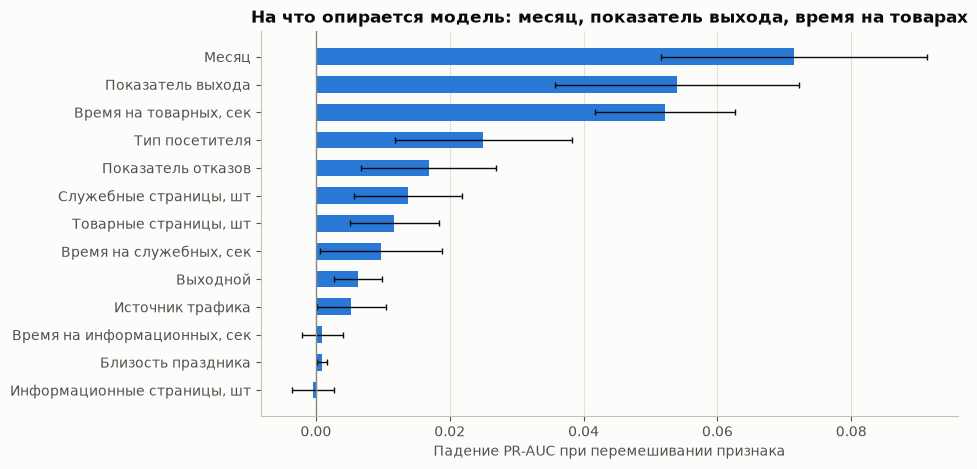

In [18]:
from src.config import FEATURE_RU
names_ru = {**FEATURE_RU, "Month": "Месяц", "VisitorType": "Тип посетителя",
            "Weekend": "Выходной", "TrafficType": "Источник трафика"}
imp = importance.sort_values("важность")
fig, ax = plt.subplots(figsize=(9, 5))
y_pos = np.arange(len(imp))
ax.barh(y_pos, imp["важность"], xerr=imp["std по фолдам"], color=BLUE, height=0.6,
        error_kw={"ecolor": "#0b0b0b", "elinewidth": 1, "capsize": 2})
ax.set_yticks(y_pos)
ax.set_yticklabels([names_ru[c] for c in imp.index])
ax.axvline(0, color=GRAY, linewidth=1)
ax.set_xlabel("Падение PR-AUC при перемешивании признака")
ax.set_title("На что опирается модель: месяц, показатель выхода, время на товарах")
ax.grid(axis="y", visible=False)
save_fig(fig, "05_permutation_importance")
plt.show()

**Что увидел.** Сильнее всего модель опирается на месяц (падение PR-AUC 0.071), показатель выхода (0.054) и время на товарных страницах (0.052). Дальше идут тип посетителя (0.025) и показатель отказов (0.017). Источник трафика (0.005) и близость праздника (0.001) почти не влияют, а информационные страницы не влияют совсем.

**Что это значит.** Модель опирается на то же, что я видел в EDA: сезон, вовлечённость в товары и то, ведут ли посещённые страницы дальше по сайту. Два наблюдения:
1. Источник трафика в 03 был самым сильным категориальным признаком, а модели он почти не нужен. Видимо, его информация уже есть в поведении: "плохие" источники приводят людей, которые быстро уходят, и это видно по показателям выхода и отказов. Это догадка, проверить её напрямую я не могу.
2. Permutation importance занижает важность связанных признаков. Если перемешать число товарных страниц, модель частично восстановит эту информацию из времени на них (корреляция Спирмена 0.88). Поэтому "товарные страницы, шт" не стоит считать неважными.

## 9. Финальная проверка на тесте

Всё выбрано на train: модель (подобранный лес без весов), гиперпараметры, порог 0.224. Теперь **один раз** обучаю модель на всём train и считаю метрики на тесте. Для сравнения в той же ячейке считаю на тесте подобранную регрессию и справочную модель с `PageValues`. Это не влияет на выбор: он уже сделан.

In [19]:
X_test_full, y_test = split_xy(load_test())

lr_tuned_pipe = make_model_pipeline(LogisticRegression(max_iter=5000, **lr_best_params),
                                    MAIN_NUMERIC, MAIN_CATEGORICAL)
final_models = {
    "Лес (подобранный), финальная": (rf_tuned_pipe, FEATURES),
    "ЛР (подобранная)": (lr_tuned_pipe, FEATURES),
    "Справка: лес + PageValues (утечка)": (rf_pv_pipe, FEATURES_PV),
}
oof_thresholds = {
    "Лес (подобранный), финальная": threshold,
    "ЛР (подобранная)": summary.loc["ЛР (подобранная)", "порог (max F1)"],
    "Справка: лес + PageValues (утечка)": summary.loc["Справка: лес + PageValues (утечка)", "порог (max F1)"],
}
test_rows, test_proba = [], {}
for name, (pipe, cols) in final_models.items():
    pipe.fit(X_full[cols], y)
    p = pipe.predict_proba(X_test_full[cols])[:, 1]
    test_proba[name] = p
    test_rows.append({"модель": name, **metrics_at_threshold(y_test, p, oof_thresholds[name])})
test_results = pd.DataFrame(test_rows).set_index("модель")
test_results

,ROC-AUC,PR-AUC,порог,precision,recall,F1,доля отмеченных
модель,,,,,,,
"Лес (подобранный), финальная",0.764,0.356,0.224,0.320,0.537,0.401,0.26
ЛР (подобранная),0.737,0.321,0.198,0.285,0.607,0.388,0.33
Справка: лес + PageValues (утечка),0.923,0.733,0.319,0.616,0.715,0.662,0.18


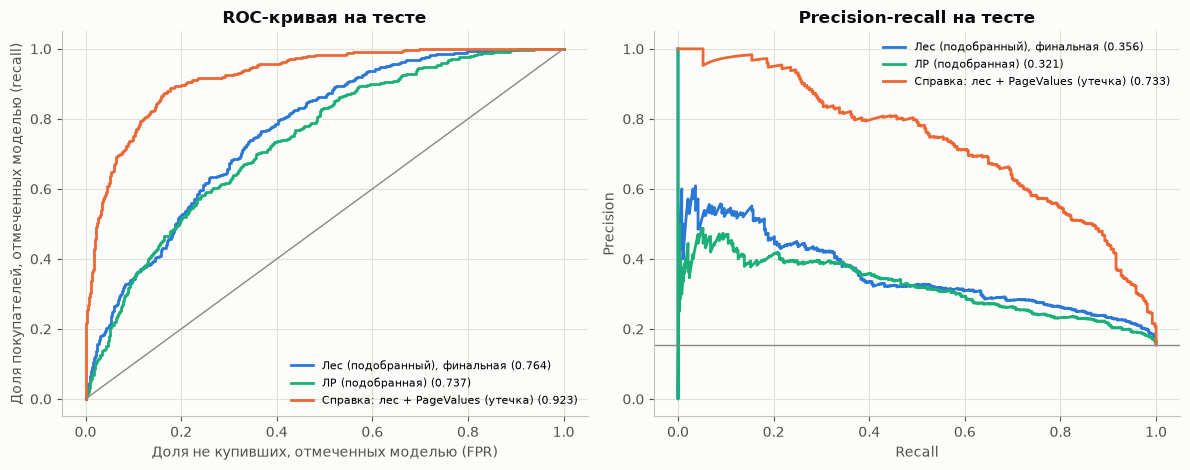

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
colors = {"Лес (подобранный), финальная": BLUE, "ЛР (подобранная)": AQUA,
          "Справка: лес + PageValues (утечка)": ORANGE}
for name, p in test_proba.items():
    fpr, tpr, _ = roc_curve(y_test, p)
    axes[0].plot(fpr, tpr, color=colors[name], label=f"{name} ({test_results.loc[name, 'ROC-AUC']:.3f})")
    pr, rc, _ = precision_recall_curve(y_test, p)
    axes[1].plot(rc, pr, color=colors[name], label=f"{name} ({test_results.loc[name, 'PR-AUC']:.3f})")
axes[0].plot([0, 1], [0, 1], color=GRAY, linewidth=1)
axes[0].set_xlabel("Доля не купивших, отмеченных моделью (FPR)")
axes[0].set_ylabel("Доля покупателей, отмеченных моделью (recall)")
axes[0].set_title("ROC-кривая на тесте")
axes[1].axhline(y_test.mean(), color=GRAY, linewidth=1)
axes[1].set_xlabel("Recall")
axes[1].set_ylabel("Precision")
axes[1].set_title("Precision-recall на тесте")
for ax in axes:
    ax.legend(fontsize=8, loc="lower right" if ax is axes[0] else "upper right")
fig.tight_layout()
save_fig(fig, "05_test_curves")
plt.show()

In [21]:
# Насколько точна оценка на тесте: бутстрэп по сессиям теста (модели не переобучаются)
from sklearn.metrics import average_precision_score, roc_auc_score
rng = np.random.default_rng(RANDOM_STATE)
yt = y_test.to_numpy()
p_rf, p_lr = test_proba["Лес (подобранный), финальная"], test_proba["ЛР (подобранная)"]
boot = []
for _ in range(1000):
    idx = rng.integers(0, len(yt), len(yt))
    boot.append((roc_auc_score(yt[idx], p_rf[idx]), average_precision_score(yt[idx], p_rf[idx]),
                 average_precision_score(yt[idx], p_rf[idx]) - average_precision_score(yt[idx], p_lr[idx])))
boot = np.array(boot)
for i, label in enumerate(["ROC-AUC леса", "PR-AUC леса", "PR-AUC: лес минус регрессия"]):
    lo, hi = np.percentile(boot[:, i], [2.5, 97.5])
    print(f"{label}: 95% интервал [{lo:.3f}; {hi:.3f}]")
print(f"Доля бутстрэп-выборок, где лес лучше регрессии по PR-AUC: {(boot[:, 2] > 0).mean():.1%}")

ROC-AUC леса: 95% интервал [0.740; 0.787]
PR-AUC леса: 95% интервал [0.313; 0.411]
PR-AUC: лес минус регрессия: 95% интервал [0.010; 0.061]
Доля бутстрэп-выборок, где лес лучше регрессии по PR-AUC: 99.6%


In [22]:
final_pipe = final_models["Лес (подобранный), финальная"][0]
p_test = test_proba["Лес (подобранный), финальная"]
cm = confusion_matrix(y_test, (p_test >= threshold).astype(int))
pd.DataFrame(cm, index=["на самом деле не купил", "на самом деле купил"],
             columns=["модель: не купит", "модель: купит"])

,модель: не купит,модель: купит
на самом деле не купил,1648,436
на самом деле купил,177,205


**Что увидел.** На тесте у финального леса ROC-AUC 0.764, PR-AUC 0.356 (на кросс-валидации было 0.786 и 0.387). При пороге 0.224: precision 0.320, recall 0.537, F1 0.401. Регрессия на тесте: PR-AUC 0.321. Справочная модель с `PageValues`: PR-AUC 0.733.

**Что это значит.** На тесте результат хуже, чем на кросс-валидации: PR-AUC 0.356 против 0.387. Но 95% бутстрэп-интервал PR-AUC на тесте от 0.313 до 0.411. На 2466 сессиях (382 покупки) оценка сама по себе неточная, и значение с кросс-валидации попадает в этот интервал. Часть разницы объясняется оптимизмом от выбора лучшей из 40 конфигураций.

Порядок моделей сохранился. На тесте лес лучше регрессии на 0.035 PR-AUC: 95% интервал разницы от 0.010 до 0.061, лес лучше в 99.6% бутстрэп-выборок. Модель с утечкой и на тесте почти вдвое лучше (0.733).

Матрица ошибок при пороге 0.224: модель отметила 641 сессию: 205 покупателей и 436 ушедших без покупки. Пропустила 177 покупателей.

## Сохранение результатов для 06 и 07

In [23]:
MODELS_DIR.mkdir(exist_ok=True)
joblib.dump(final_pipe, FINAL_MODEL_PATH)
with open(MODELS_DIR / "final_model_params.json", "w", encoding="utf-8") as f:
    json.dump({"model": "RandomForestClassifier", "params": rf_best_params,
               "features": FEATURES, "threshold_max_f1_oof": threshold}, f,
              ensure_ascii=False, indent=2, default=str)

pd.DataFrame({TARGET: y, "p_oof": p_oof}, index=X.index).to_csv(OOF_PATH)
pd.DataFrame({TARGET: y_test, "p": p_test}, index=X_test_full.index).to_csv(TEST_PRED_PATH)
print("Сохранено:", FINAL_MODEL_PATH.name, OOF_PATH.name, TEST_PRED_PATH.name)

Сохранено: final_model.joblib oof_train.csv test_predictions.csv


## Итоги

- **Лучшая честная модель: подобранный случайный лес.** PR-AUC 0.387 на кросс-валидации и 0.356 на тесте (у бейзлайна 0.155), ROC-AUC 0.786 и 0.764.
- **Лес лучше логистической регрессии, но ненамного:** +0.045 PR-AUC на CV, +0.035 на тесте. Бустинг не лучше леса.
- **Подбор гиперпараметров** дал лесу +0.020 PR-AUC (главное не давать деревьям листья из одной сессии), регрессии всего +0.003.
- **Веса классов не нужны:** качество то же, а вероятности завышены (средняя оценка 0.385 при реальной доле 0.155). Вместо них использую порог 0.224 по максимуму F1 (на тесте precision 0.320, recall 0.537).
- **Модель с `PageValues`** дала бы на тесте PR-AUC 0.733, вдвое больше, но за счёт утечки.

## Что не получилось или удивило

- Тест оказался хуже кросс-валидации на 0.03 PR-AUC. Это в пределах статистической погрешности, но опираться на цифру с CV как на окончательную не стоит.
- Бустинг, который обычно выигрывает на табличных данных, здесь не дал прироста. Похоже, предел задают признаки, а не модель: без `PageValues` в данных мало информации о намерении купить.
- Источник трафика, значимый в 03, оказался одним из наименее нужных модели признаков.

## Новые идеи

- В 07 порог нужно выбирать по прибыли, а не по F1: модель хорошо *сортирует*, но кому давать промокод, решает экономика.
- Модель, обученная на неполных сессиях (первые N страниц), была бы честнее для сценария "промокод во время визита".

## Следующие шаги

- **В ноутбуке 06** разберу ошибки: кто такие сессии, которые модель считает "покупателями", а они уходят без покупки (ложноположительные).
- **При большем времени:** калибровка вероятностей регрессии и бустинга, подбор гиперпараметров на повторной кросс-валидации, SHAP-значения для объяснения отдельных предсказаний.